# Task 2 — Vision-language models and visual grounding

Run this notebook top to bottom on Colab Pro with an L4 GPU and High RAM. It follows the assignment's fixed 196-token, three-stage recipe. The final sections display saved evidence by research question. A local rerun only rebuilds and displays evidence from `Task_2/results/`.


## Common setup — mount Drive and copy code

Upload the complete `Task_2` code folder to `MyDrive/ATML_PA3/Task_2/` before running. Data downloads into the Colab VM; feature chunks, checkpoints, histories, predictions, metrics, and figures are copied to Drive. Running the notebook again restores them.


In [1]:
import sys, time, shutil
from pathlib import Path

SESSION_STARTED = time.monotonic()
import importlib.util
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
LOCAL_REPLAY = not IN_COLAB
DRIVE_PROJECT = Path("/content/drive/MyDrive/ATML_PA3")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    drive_task = DRIVE_PROJECT / "Task_2"
    if not (drive_task / "configs" / "base.yaml").is_file():
        raise FileNotFoundError("Upload Task_2 to MyDrive/ATML_PA3/Task_2 first.")
    task_dir = Path("/content/Task_2")
    shutil.copytree(drive_task, task_dir, dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns("results", "__pycache__", "*.pyc"))
else:
    task_dir = Path.cwd()
    if not (task_dir / "configs" / "base.yaml").is_file():
        task_dir = task_dir / "Task_2"
    if not (task_dir / "configs" / "base.yaml").is_file():
        raise FileNotFoundError("Run this notebook from the repository root or Task_2.")
sys.path.insert(0, str(task_dir.resolve()))
print("Task 2 code:", task_dir)
print("Mode:", "Colab compute" if IN_COLAB else "local replay of saved Colab results")


Task 2 code: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_3\Task_2
Mode: local replay of saved Colab results


## Common setup — packages and runtime

The fixed assignment batch is microbatch 8 with accumulation 2. High RAM is used for the FP16 feature cache. Do not increase the training microbatch to fill VRAM; that changes the experiment.


In [2]:
if IN_COLAB:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r",
                           str(task_dir / "requirements-colab.txt")])
    import torch
    if not torch.cuda.is_available():
        raise RuntimeError("Select a Colab GPU runtime before starting Task 2.")
    import psutil
    if torch.cuda.get_device_properties(0).total_memory < 20 * 2**30:
        raise RuntimeError("Select an L4 or larger GPU (at least 20 GiB VRAM).")
    if psutil.virtual_memory().total < 40 * 2**30:
        raise RuntimeError("Enable High RAM (at least 40 GiB host RAM).")
    print("GPU:", torch.cuda.get_device_name(0),
          "| VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
    print("Host RAM GiB:", round(psutil.virtual_memory().total / 2**30, 1))


In [3]:
from common.shared import read_configuration, task_paths, seed_everything, read_json
from cloud.colab import restore_results, restore_feature_cache, sync_file, sync_small_results
from training.train import latest_checkpoint
import torch

config = read_configuration()
paths = task_paths(config)
seed_everything(config["experiment"]["seed"])
DRIVE_RESULTS = DRIVE_PROJECT / "Task_2" / "results" if IN_COLAB else None
DRIVE_DATA = DRIVE_PROJECT / "Data" / "Task_2" if IN_COLAB else None
SESSION_DEADLINE = SESSION_STARTED + 10.5 * 3600 if IN_COLAB else None
if IN_COLAB:
    restored_results = restore_results(paths["results"], DRIVE_RESULTS)
    saved_final = paths["results"] / "metrics" / "final_evaluation.json"
    saved_predictions = [paths["results"] / "predictions" / (name + ".jsonl")
                         for name in ("grounding_test", "natural_test")]
    finished = (saved_final.is_file() and all(path.is_file() for path in saved_predictions)
                and len(read_json(saved_final).get("suites", {})) == 2)
    restored_features = 0 if finished else restore_feature_cache(paths["data"], DRIVE_DATA)
    print("Restored result files:", restored_results, "| feature chunks:", restored_features)
print("Results:", paths["results"])


C:\Users\DanishZaheer\anaconda3\envs\ATML\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Results: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_3\Task_2\results


In [4]:
def sync_outputs():
    if IN_COLAB:
        sync_small_results(paths["results"], DRIVE_RESULTS)

def sync_checkpoint(path):
    if IN_COLAB:
        sync_file(path, paths["results"], DRIVE_RESULTS, verify=True)

def sync_feature_chunk(path):
    if IN_COLAB:
        sync_file(path, paths["data"], DRIVE_DATA, verify=True)
        sync_outputs()

final_path = paths["results"] / "metrics" / "final_evaluation.json"
prediction_paths = [paths["results"] / "predictions" / (name + ".jsonl")
                    for name in ("grounding_test", "natural_test")]
FINAL_COMPLETE = (final_path.is_file() and all(path.is_file() for path in prediction_paths)
                  and len(read_json(final_path).get("suites", {})) == 2)
NEED_MODEL = IN_COLAB and not FINAL_COMPLETE
print("Complete final evaluation restored:", FINAL_COMPLETE,
      "| model computation needed:", NEED_MODEL)


Complete final evaluation restored: True | model computation needed: False


### Verify saved Colab results for local replay

A local run checks the completed Colab artifacts before displaying each step. It does not load models, download data, train, or reevaluate.


In [5]:
if LOCAL_REPLAY:
    result_root = paths["results"]
    required = [
        "splits/selection.json", "histories/training.csv",
        "metrics/model_revisions.json", "metrics/feature_cache.json",
        "metrics/connector_calibration.json", "metrics/interface_diagnostic.json",
        "metrics/caption_resources.json", "metrics/instruction_resources.json",
        "metrics/natural_resources.json", "metrics/final_evaluation.json",
        "predictions/grounding_test.jsonl", "predictions/natural_test.jsonl",
        "examples/qualitative.json", "figures/grounding_label_audit.png",
    ]
    required += [f"metrics/development_{update:04d}.json" for update in
                 (0, 500, 1000, 1500, 2000, 2250, 2500, 3000, 3500, 3750, 4000, 4500)]
    saved_examples = read_json(result_root / "examples" / "qualitative.json")
    required += [f"figures/qualitative_{suite}_{item['pair_id']}.png"
                 for suite, items in saved_examples.items() for item in items]
    missing = [name for name in required if not (result_root / name).is_file()]
    if missing:
        raise FileNotFoundError("Copy saved Colab outputs to Task_2/results. Missing: " + ", ".join(missing))
    import csv
    with (result_root / "histories" / "training.csv").open(newline="", encoding="utf-8") as stream:
        updates = [int(row["update"]) for row in csv.DictReader(stream)]
    if updates != list(range(1, 4501)):
        raise RuntimeError("Saved Task 2 training history is incomplete or out of order.")
    if not FINAL_COMPLETE or read_json(final_path).get("update") != 4500:
        raise RuntimeError("Saved Task 2 final evaluation is incomplete.")
    print("Verified saved Colab run:", len(updates), "updates and", len(required),
          "required evidence files. Local replay will not train or evaluate models.")


Verified saved Colab run: 4500 updates and 32 required evidence files. Local replay will not train or evaluate models.


## Step 1 — fixed data selection and visual interface

Download official COCO 2014 and VQAv2 annotations, select the seeded caption and complementary-pair splits, and save the selected IDs before viewing results. On later sessions the saved selection is reused.


In [6]:
from data.prepare import prepare_selection, verify_selection

selection_path = paths["results"] / "splits" / "selection.json"
if selection_path.is_file():
    selection = read_json(selection_path)
elif IN_COLAB:
    selection = prepare_selection(config, paths)
    sync_outputs()
else:
    selection = None
if selection is not None:
    verify_selection(config, selection)
    print({name: len(selection[name]) for name in
           ("caption_train", "caption_dev", "grounding_train", "grounding_dev",
            "grounding_test", "natural_train", "natural_dev", "natural_test")})
else:
    print("No saved Task 2 selection found locally; evidence cells need downloaded results.")


{'caption_train': 18000, 'caption_dev': 96, 'grounding_train': 4096, 'grounding_dev': 24, 'grounding_test': 64, 'natural_train': 1536, 'natural_dev': 32, 'natural_test': 96}


### Inspect COCO-derived grounding labels before model results

The saved contact sheet shows a seeded train, development, and test pair for both presence and counting. Inspect these image labels manually before interpreting model scores; COCO annotations can be incomplete or visually ambiguous.


Saved grounding label audit:


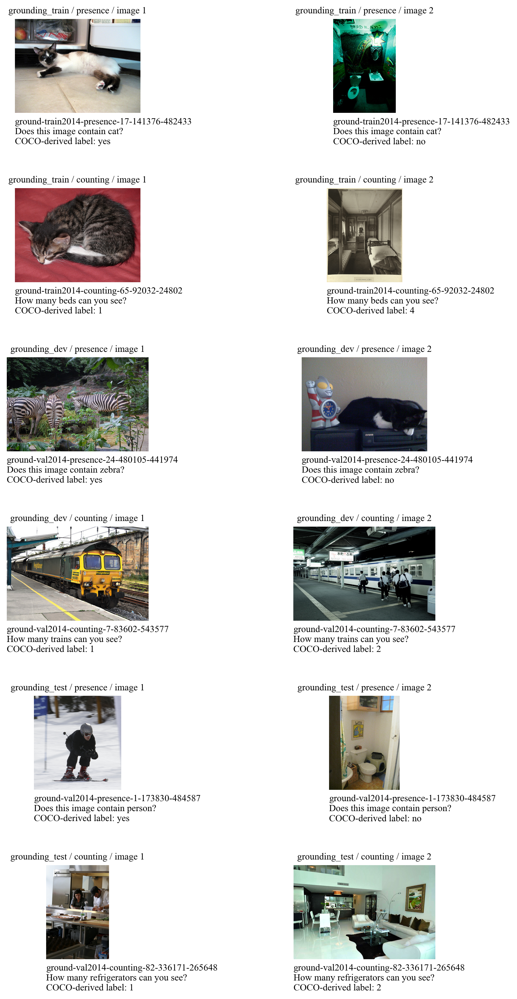

In [7]:
if IN_COLAB:
    from data.inspection import build_grounding_label_audit
from IPython.display import display, Image as NotebookImage

audit_path = paths["results"] / "figures" / "grounding_label_audit.png"
if IN_COLAB and selection is not None:
    audit_pairs = build_grounding_label_audit(selection, paths)
    sync_outputs()
    print("Grounding label audit pairs:", [item["pair_id"] for item in audit_pairs])
if audit_path.is_file():
    print("Saved grounding label audit:")
    display(NotebookImage(filename=str(audit_path)))
else:
    print("Grounding label audit not available yet.")


### Download pinned models and cache SigLIP features

SigLIP extracts the final 196 post-layer-normalized patch features once. The cache is FP16, copied chunk by chunk to Drive, and loaded into host RAM. The vision encoder is removed from the GPU before Qwen is initialized.


In [8]:
if NEED_MODEL:
    from models.download import ensure_models
    from data.features import feature_cache_complete, cache_features, FeatureStore

model_dirs = {}
revision_path = paths["results"] / "metrics" / "model_revisions.json"
if NEED_MODEL:
    missing_features = not feature_cache_complete(selection, paths)
    components = ("vision", "language") if missing_features else ("language",)
    model_dirs, model_locks = ensure_models(config, paths, components=components)
    sync_outputs()
else:
    model_locks = read_json(revision_path) if revision_path.is_file() else None
print("Pinned model revisions:", model_locks)


Pinned model revisions: {'vision': {'repo_id': 'google/siglip-base-patch16-224', 'revision': '7fd15f0689c79d79e38b1c2e2e2370a7bf2761ed'}, 'language': {'repo_id': 'Qwen/Qwen3-0.6B', 'revision': 'c1899de289a04d12100db370d81485cdf75e47ca'}}


In [9]:
cache_path = paths["results"] / "metrics" / "feature_cache.json"
if NEED_MODEL:
    cache_report = cache_features(config, paths, selection, model_dirs.get("vision"),
                                  chunk_callback=sync_feature_chunk)
    sync_outputs()
else:
    cache_report = read_json(cache_path) if cache_path.is_file() else None
print("SigLIP feature-cache result:", cache_report)


SigLIP feature-cache result: {'images': 9253, 'remaining_chunks': 0, 'seconds_all_sessions': 930.757027927, 'peak_gpu_gib_all_sessions': 0.7313618659973145, 'encoder_batch': 128, 'feature_dtype': 'float16', 'post_layernorm_applied_by_siglip_forward': True}


In [10]:
store = FeatureStore(paths["data"], selection) if NEED_MODEL else None
if store is not None:
    print("Cached images in host RAM:", len(store))
    print("SigLIP GPU allocation after cache:",
          round(torch.cuda.memory_allocated() / 2**30, 2), "GiB")
elif cache_report is not None:
    print("Saved Colab cache:", cache_report["images"], "images,",
          cache_report["remaining_chunks"], "chunks remaining")


Saved Colab cache: 9253 images, 0 chunks remaining


### Check the Qwen visual interface

Build the continuous-token connector, calibrate its output magnitude on training images, and check masks, frozen parameters, and gradient flow before any optimizer update.


In [11]:
if NEED_MODEL:
    from training.train import TrainingSession

session = TrainingSession(config, paths, selection, store, model_dirs["language"]) if NEED_MODEL else None
diagnostic_path = paths["results"] / "metrics" / "interface_diagnostic.json"
calibration_path = paths["results"] / "metrics" / "connector_calibration.json"
if session is not None:
    diagnostic = read_json(diagnostic_path) if diagnostic_path.is_file() else session.check_interface()
    sync_outputs()
    print("Resuming at update:", session.update)
else:
    diagnostic = read_json(diagnostic_path) if diagnostic_path.is_file() else None
print("Visual-interface diagnostic:", diagnostic)
if calibration_path.is_file():
    print("Training-only connector calibration:", read_json(calibration_path))


Visual-interface diagnostic: {'feature_shape': [2, 196, 768], 'feature_dtype': 'torch.float16', 'connector_gradient_norm': 114.19754028320312, 'supervised_tokens': [12, 17], 'original_qwen_trainable_parameters': 0, 'connector_scale': 0.05802774056792259}
Training-only connector calibration: {'rule': 'text_embedding_rms / initial_connector_rms', 'training_images': 256, 'text_rms': 0.029202857986092567, 'visual_rms_before': 0.5032568573951721, 'scale': 0.05802774056792259}


## Step 2 — caption alignment

Train only the connector for two seeded passes over 18,000 caption examples: 2,250 updates. The unchanged model receives development evaluation at update 0; subsequent checks use the assignment schedule.


In [12]:
if NEED_MODEL:
    from evaluation.evaluate import run_development, run_final_evaluation
from IPython.display import display
import pandas as pd

def check_development(model, update):
    return run_development(model, selection, store, paths, update)

def show_saved_stage(stage, end_update):
    resource_path = paths["results"] / "metrics" / (stage + "_resources.json")
    report = read_json(resource_path)
    if report["end_update"] != end_update:
        raise RuntimeError(f"{stage}: saved stage ends at {report['end_update']}, expected {end_update}.")
    development = read_json(paths["results"] / "metrics" / f"development_{end_update:04d}.json")
    row = {
        "update": end_update,
        "caption_loss": development["caption_reference_loss"],
        "grounding_NLL": development["suites"]["grounding_dev"]["correct_nll"],
        "natural_NLL": development["suites"]["natural_dev"]["correct_nll"],
        "grounding_swap_penalty": development["suites"]["grounding_dev"]["image_swap_penalty"],
        "natural_swap_penalty": development["suites"]["natural_dev"]["image_swap_penalty"],
        "stage_minutes": report["seconds_all_sessions"] / 60,
        "peak_GPU_GiB": report["peak_gpu_gib_all_sessions"],
        "trainable_parameters": report["trainable_parameters"],
    }
    print(f"{stage}: saved Colab stage complete at update {end_update}/4500")
    display(pd.DataFrame([row]).round(4))
    print("Pair draws:", report["mixture_draw_counts"])
    return report


In [13]:
if session is not None:
    caption_report = session.run_stage(
        "caption", development_callback=check_development,
        checkpoint_callback=sync_checkpoint, result_callback=sync_outputs,
        deadline=SESSION_DEADLINE)
    print(caption_report)
else:
    caption_report = show_saved_stage("caption", 2250)


caption: saved Colab stage complete at update 2250/4500


,update,caption_loss,grounding_NLL,natural_NLL,grounding_swap_penalty,natural_swap_penalty,stage_minutes,peak_GPU_GiB,trainable_parameters
0,2250,2.2112,9.8923,9.2396,0.0181,0.2162,46.4875,5.5565,1837056


Pair draws: {'presence': 0, 'counting': 0, 'caption': 0, 'natural': 0}


## Step 3 — visual instruction tuning

Continue the same connector for 1,500 updates. Each seeded pair draw chooses presence (50%), counting (25%), or two caption replay examples (25%). Enable rank-16 LoRA on Qwen attention projections; keep all original Qwen parameters frozen.


In [14]:
if session is not None:
    instruction_report = session.run_stage(
        "instruction", development_callback=check_development,
        checkpoint_callback=sync_checkpoint, result_callback=sync_outputs,
        deadline=SESSION_DEADLINE)
    print(instruction_report)
else:
    instruction_report = show_saved_stage("instruction", 3750)


instruction: saved Colab stage complete at update 3750/4500


,update,caption_loss,grounding_NLL,natural_NLL,grounding_swap_penalty,natural_swap_penalty,stage_minutes,peak_GPU_GiB,trainable_parameters
0,3750,2.2229,0.7526,1.7322,2.6882,1.5035,34.8602,5.3487,6424576


Pair draws: {'presence': 5964, 'counting': 3146, 'caption': 2890, 'natural': 0}


## Step 4 — natural VQA specialization

Continue for 750 updates with complete natural VQAv2 pairs (70%), presence replay (10%), counting replay (10%), and caption replay (10%). Save update 4,500 and the final connector/adapter export.


In [15]:
if session is not None:
    natural_report = session.run_stage(
        "natural", development_callback=check_development,
        checkpoint_callback=sync_checkpoint, result_callback=sync_outputs,
        deadline=SESSION_DEADLINE)
    print(natural_report)
else:
    natural_report = show_saved_stage("natural", 4500)


natural: saved Colab stage complete at update 4500/4500


,update,caption_loss,grounding_NLL,natural_NLL,grounding_swap_penalty,natural_swap_penalty,stage_minutes,peak_GPU_GiB,trainable_parameters
0,4500,2.2566,0.6434,0.9859,1.8822,1.4466,17.498,5.2998,6424576


Pair draws: {'presence': 600, 'counting': 625, 'caption': 593, 'natural': 4182}


## Step 5 — held-out image controls

At the final model, score each test suite under correct, complementary, mismatched, and no-image inputs. Generation uses greedy batch-8 decoding capped at 16 new tokens. The saved mismatched map excludes each original pair.


In [16]:
if session is not None:
    if session.update != 4500:
        raise RuntimeError("Final evaluation requires all 4,500 optimizer updates.")
    final_results = run_final_evaluation(session.model, selection, store, config, paths,
                                         result_callback=sync_outputs)
    sync_outputs()
elif final_path.is_file():
    final_results = read_json(final_path)
else:
    final_results = None

if final_results is not None:
    print("Final evaluation saved at update:", final_results["update"],
          "| pair-bootstrap resamples:", final_results["bootstrap_pairs"])
    rows = []
    for suite, data in final_results["suites"].items():
        for condition in config["evaluation"]["conditions"]:
            scores = data["conditions"][condition]
            rows.append({"suite": suite, "condition": condition,
                         "accuracy": scores["accuracy"]["mean"],
                         "pair_accuracy": scores["pair_accuracy"]["mean"],
                         "reference_NLL": scores["reference_nll"]["mean"]})
    display(pd.DataFrame(rows).round(4))
else:
    print("Final evaluation results are not available yet.")


Final evaluation saved at update: 4500 | pair-bootstrap resamples: 4000


,suite,condition,accuracy,pair_accuracy,reference_NLL
0,grounding_test,correct,0.7031,0.4688,0.7805
1,grounding_test,complementary,0.2031,0.0156,2.7348
2,grounding_test,mismatched,0.5000,0.0469,1.7405
3,grounding_test,no_image,0.3906,0.0000,1.5280
4,natural_test,correct,0.5391,0.2604,1.4475
5,natural_test,complementary,0.3240,0.0729,2.5067
6,natural_test,mismatched,0.3427,0.0417,2.2488
7,natural_test,no_image,0.3411,0.0000,2.4383


## Step 6 — build report evidence from saved files

These cells regenerate CSV tables and 300 dpi PNG figures from saved results. They never load Qwen or train when run locally. Times New Roman text is set to 10 pt.


In [17]:
from evaluation.evidence import build_evidence
from IPython.display import display, Image
import pandas as pd

EVIDENCE_READY = (final_results is not None and
                  set(final_results.get("suites", {})) == {"grounding_test", "natural_test"} and
                  (paths["results"] / "histories" / "training.csv").is_file())
evidence = build_evidence(paths) if EVIDENCE_READY else None
if evidence is not None:
    sync_outputs()
    print("Evidence tables and figures saved in", paths["results"])
else:
    print("Complete saved metrics and training history are required to build evidence.")


Evidence tables and figures saved in C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_3\Task_2\results


## Required evidence — RQ1: learning the visual interface

Inspect training loss, caption reference loss, VQA reference NLL, and image-swap penalty at the baseline, scheduled updates, and stage boundaries. Use the saved values when writing your own report analysis.


,update,suite,caption_reference_loss,correct_nll,complementary_nll,no_image_nll,image_swap_penalty
0,0,caption,5.3115,NaN,NaN,NaN,NaN
1,0,grounding_dev,NaN,7.0264,7.0023,5.6091,-0.0241
2,0,natural_dev,NaN,9.8707,9.9945,8.7679,0.1238
3,500,caption,2.5110,NaN,NaN,NaN,NaN
4,500,grounding_dev,NaN,4.5577,4.6627,5.6091,0.1050
5,500,natural_dev,NaN,5.5891,5.6179,8.7679,0.0288
6,1000,caption,2.3242,NaN,NaN,NaN,NaN
7,1000,grounding_dev,NaN,8.5388,8.7143,5.6091,0.1755
8,1000,natural_dev,NaN,9.2430,9.4005,8.7679,0.1575
9,1500,caption,2.2509,NaN,NaN,NaN,NaN


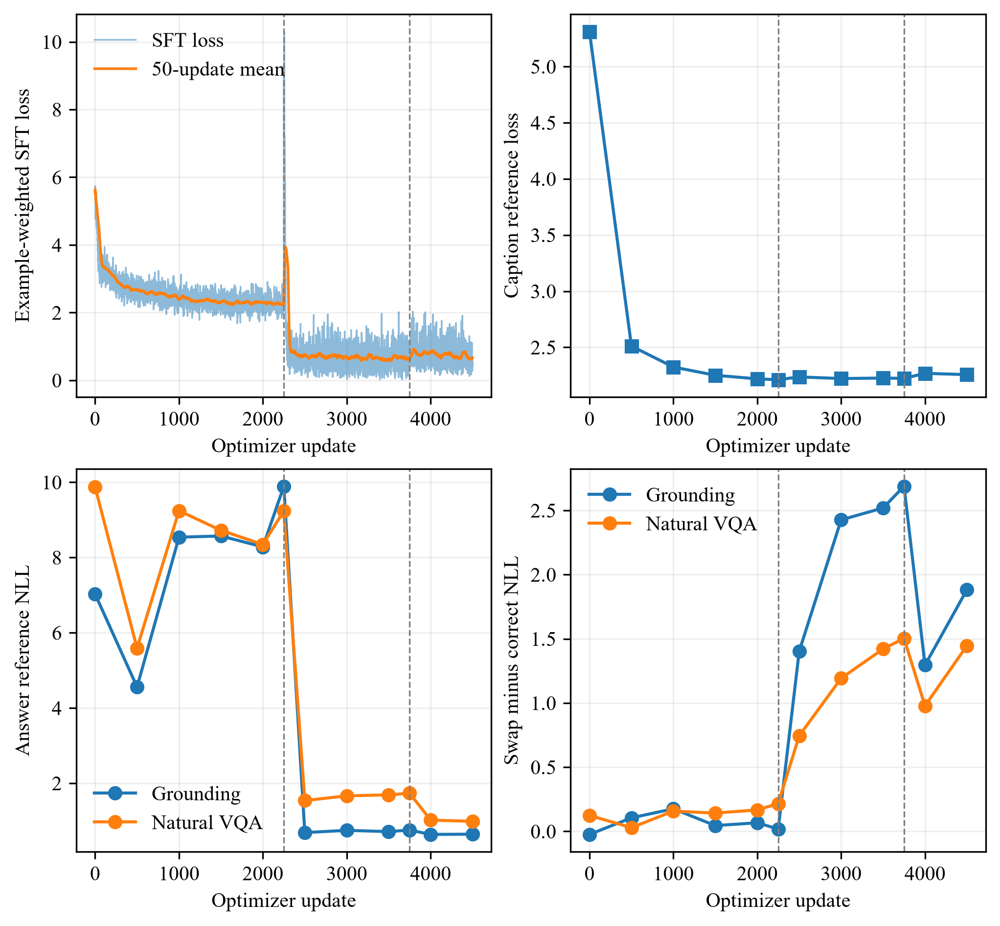

In [18]:
if evidence is not None:
    display(evidence["development"].round(4))
    display(Image(filename=str(paths["results"] / "figures" / "rq1_curriculum.png")))


## Required evidence — RQ2: grounding and generalization

Compare the two held-out suites separately across all four image inputs. The table includes accuracy, pair accuracy, answer identity, empty outputs, reference NLL, generation time, and bootstrap intervals. Under a complementary swap, partner-answer accuracy distinguishes following the new image from merely changing the answer.


,suite,condition,accuracy,accuracy_ci_low,accuracy_ci_high,partner_accuracy,unsupported_answer_rate,pair_accuracy,identical_answer_rate,empty_answer_rate,reference_nll,generation_seconds_per_answer
0,grounding_test,correct,0.7031,0.6250,0.7734,0.2031,0.0938,0.4688,0.4062,0.0,0.7805,0.0197
1,grounding_test,complementary,0.2031,0.1406,0.2656,0.7031,0.0938,0.0156,0.4062,0.0,2.7348,0.0196
2,grounding_test,mismatched,0.5000,0.4609,0.5391,0.4297,0.0703,0.0469,0.8281,0.0,1.7405,0.0195
3,grounding_test,no_image,0.3906,0.3359,0.4375,0.3906,0.2188,0.0000,1.0000,0.0,1.5280,0.0178
4,natural_test,correct,0.5391,0.4693,0.6078,0.3240,0.2135,0.2604,0.5000,0.0,1.4475,0.0249
5,natural_test,complementary,0.3240,0.2609,0.3880,0.5391,0.2135,0.0729,0.5000,0.0,2.5067,0.0252
6,natural_test,mismatched,0.3427,0.2849,0.4052,0.3401,0.3906,0.0417,0.6771,0.0,2.2488,0.0232
7,natural_test,no_image,0.3411,0.2870,0.3943,0.3411,0.3958,0.0000,1.0000,0.0,2.4383,0.0404


,suite,condition,question_type,accuracy,partner_accuracy,unsupported_answer_rate,pair_accuracy,identical_answer_rate,empty_answer_rate,reference_nll,generation_seconds_per_answer
0,grounding_test,correct,presence,0.9219,0.0781,0.0000,0.8438,0.1562,0.0,0.2427,0.0198
1,grounding_test,correct,counting,0.4844,0.3281,0.1875,0.0938,0.6562,0.0,1.3183,0.0197
2,grounding_test,complementary,presence,0.0781,0.9219,0.0000,0.0000,0.1562,0.0,3.3093,0.0197
3,grounding_test,complementary,counting,0.3281,0.4844,0.1875,0.0312,0.6562,0.0,2.1603,0.0194
4,grounding_test,mismatched,presence,0.5000,0.5000,0.0000,0.0312,0.9375,0.0,1.8647,0.0197
5,grounding_test,mismatched,counting,0.5000,0.3594,0.1406,0.0625,0.7188,0.0,1.6163,0.0193
6,grounding_test,no_image,presence,0.5000,0.5000,0.0000,0.0000,1.0000,0.0,1.6759,0.0178
7,grounding_test,no_image,counting,0.2812,0.2812,0.4375,0.0000,1.0000,0.0,1.3802,0.0177
8,natural_test,correct,yes/no,0.6056,0.5028,0.0000,0.1944,0.7222,0.0,0.7668,0.0195
9,natural_test,correct,number,0.5083,0.3083,0.2708,0.2917,0.2500,0.0,1.5294,0.0209


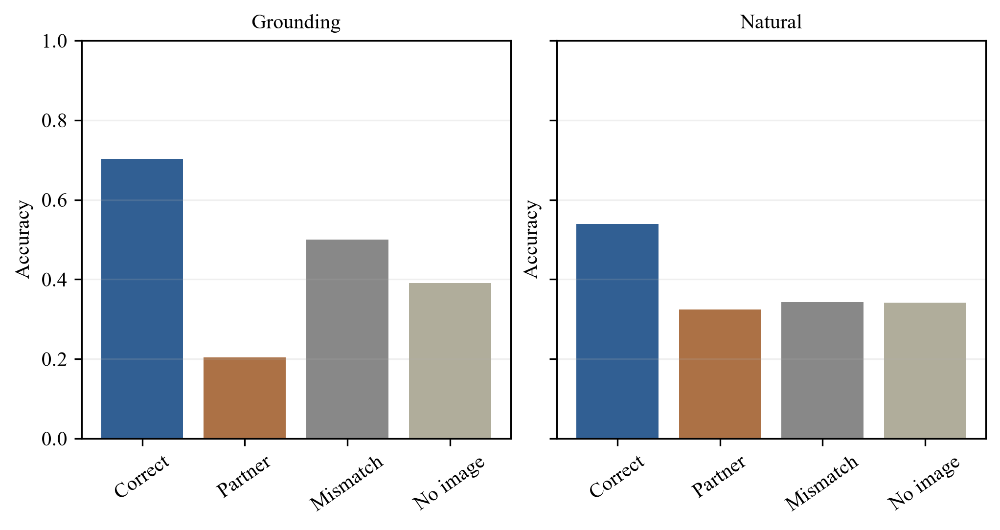

In [19]:
if evidence is not None:
    columns = ["suite", "condition", "accuracy", "accuracy_ci_low", "accuracy_ci_high",
               "partner_accuracy", "unsupported_answer_rate", "pair_accuracy",
               "identical_answer_rate", "empty_answer_rate", "reference_nll",
               "generation_seconds_per_answer"]
    display(evidence["final"][columns].round(4))
    display(evidence["types"].round(4))
    display(Image(filename=str(paths["results"] / "figures" / "rq2_image_controls.png")))


## Required evidence — RQ3: measuring image use

Compare correct-image advantages in accuracy and NLL with 4,000 paired bootstrap resamples. Inspect pair-level consistency and aligned examples selected by the saved deterministic rule. A changed answer under a swap is not sufficient evidence of correctness.


,suite,comparison,mean,ci95_low,ci95_high
0,grounding_test,correct_advantage_accuracy,0.5000,0.3750,0.6172
1,grounding_test,correct_advantage_reference_nll,1.9543,1.4895,2.4208
2,natural_test,correct_advantage_accuracy,0.2151,0.1156,0.3167
3,natural_test,correct_advantage_reference_nll,1.0591,0.6941,1.4577


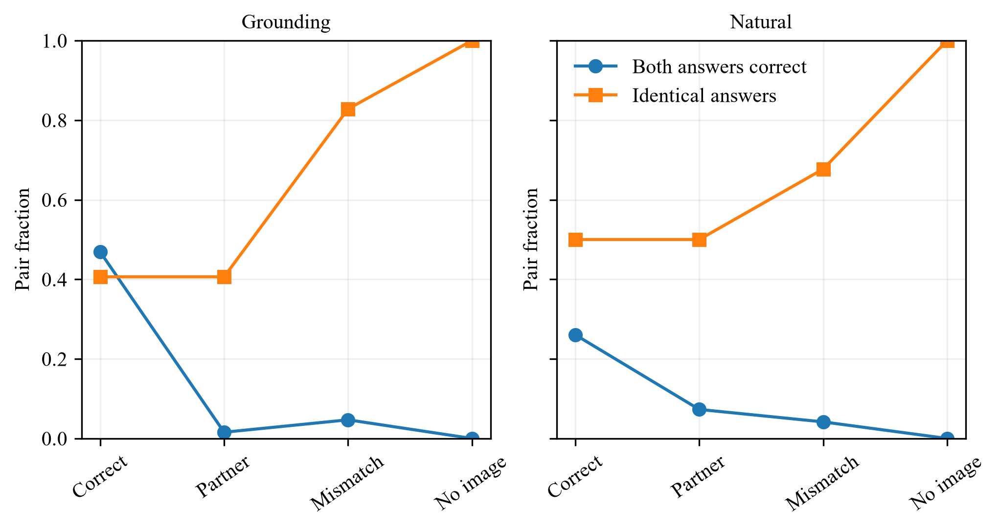

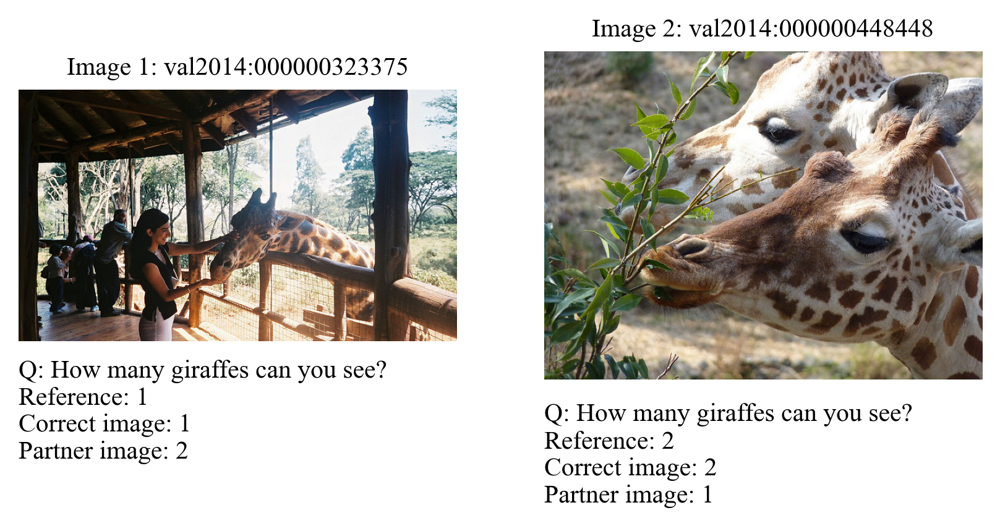

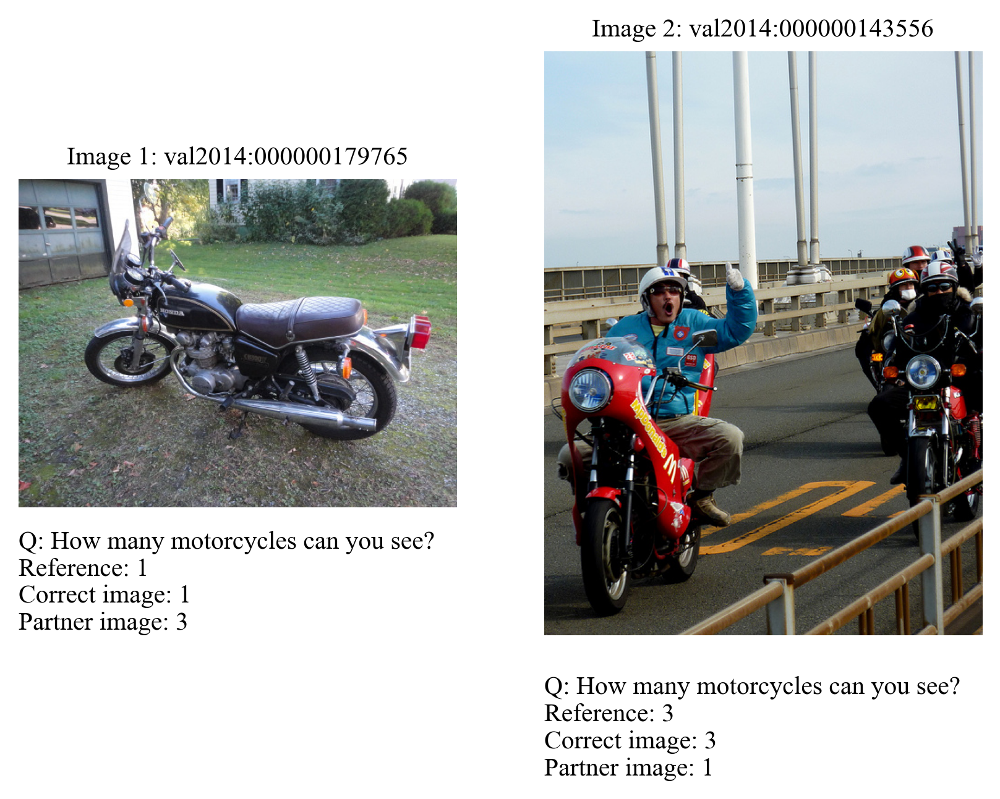

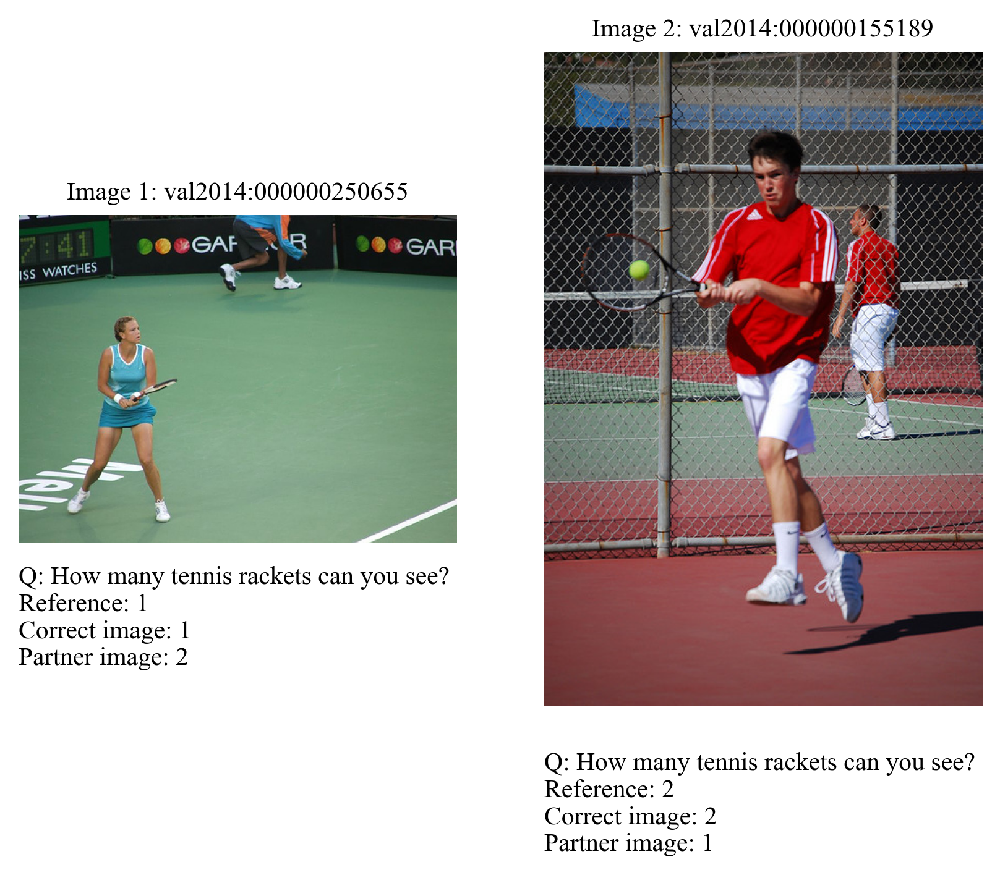

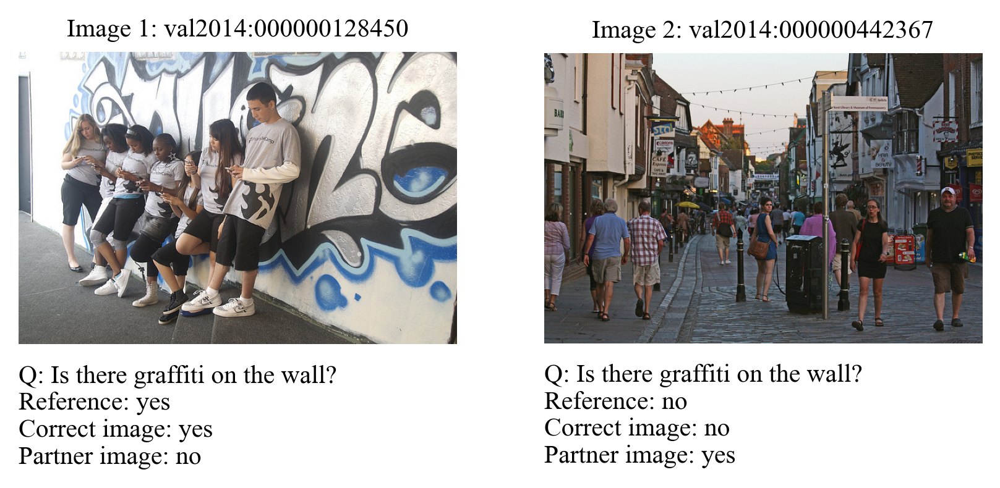

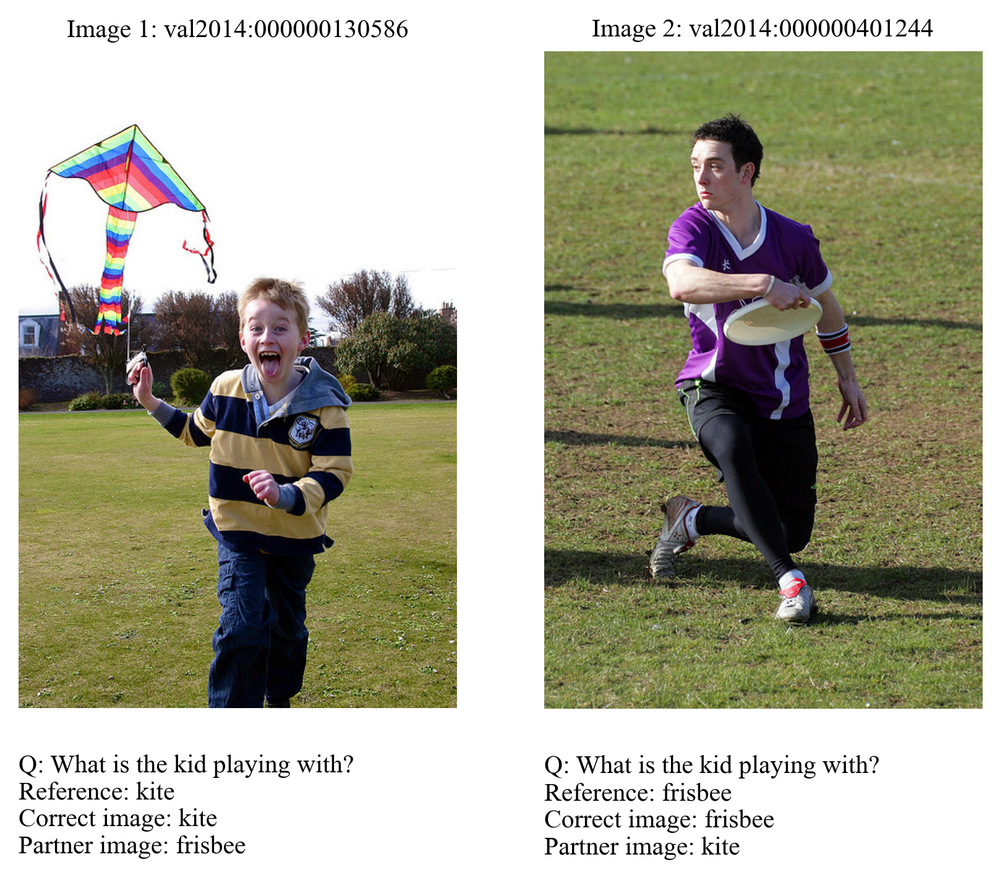

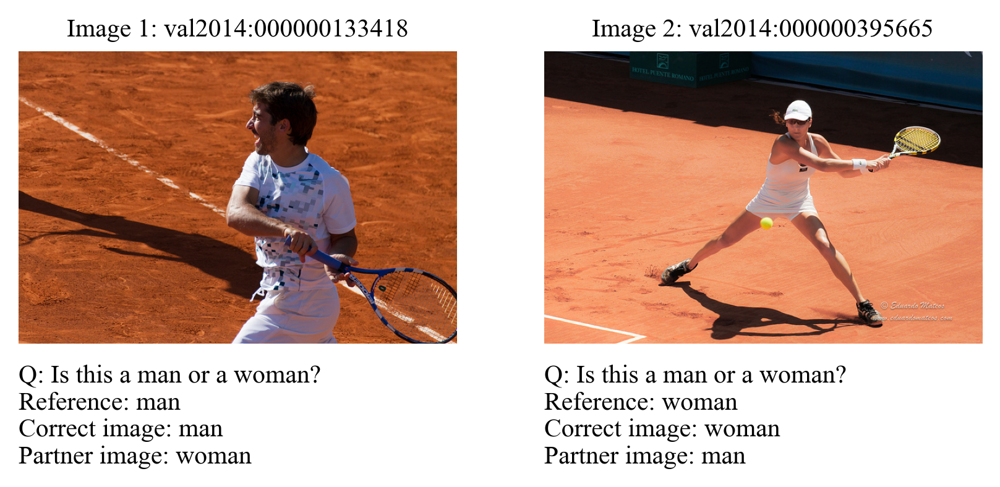

In [20]:
if evidence is not None:
    display(pd.read_csv(paths["results"] / "metrics" / "correct_image_advantages.csv").round(4))
    display(Image(filename=str(paths["results"] / "figures" / "rq3_pair_diagnostics.png")))
    for suite, items in evidence["examples"].items():
        for item in items:
            display(Image(filename=str(paths["results"] / "figures" /
                                       ("qualitative_" + suite + "_" + item["pair_id"] + ".png"))))


## Required evidence — RQ4: capabilities and cost

Read feature-caching and training time, peak GPU allocation, stage-specific trainable parameter counts, and final generation time per answer. The GPU may remain partly empty because the assignment fixes the training batch and frozen-feature design.


In [21]:
if evidence is not None:
    display(evidence["resources"].round(3))
    display(evidence["final"][["suite", "condition", "generation_seconds_per_answer",
                               "accuracy", "reference_nll"]].round(4))
    print("Checkpoint files:")
    for path in sorted((paths["results"] / "checkpoints").glob("*_weights.pt")):
        print(path.name, round(path.stat().st_size / 2**20, 1), "MiB")


,stage,seconds,peak_gpu_gib,trainable_parameters,stage_export_mib
0,feature_cache,930.757,0.731,0,NaN
1,caption,2789.253,5.557,1837056,7.011
2,instruction,2091.611,5.349,6424576,24.589
3,natural,1049.882,5.300,6424576,24.588


,suite,condition,generation_seconds_per_answer,accuracy,reference_nll
0,grounding_test,correct,0.0197,0.7031,0.7805
1,grounding_test,complementary,0.0196,0.2031,2.7348
2,grounding_test,mismatched,0.0195,0.5000,1.7405
3,grounding_test,no_image,0.0178,0.3906,1.5280
4,natural_test,correct,0.0249,0.5391,1.4475
5,natural_test,complementary,0.0252,0.3240,2.5067
6,natural_test,mismatched,0.0232,0.3427,2.2488
7,natural_test,no_image,0.0404,0.3411,2.4383


Checkpoint files:
caption_weights.pt 7.0 MiB
instruction_weights.pt 24.6 MiB
natural_weights.pt 24.6 MiB


## Completion checks

The final run should have update 4,500, both test suites, all development evaluations, two test prediction files, and RQ1–RQ4 evidence. The saved files under `Task_2/results/` support a local evidence-only rerun.


In [22]:
if evidence is not None:
    updates = sorted(int(path.stem.split("_")[-1]) for path in
                     (paths["results"] / "metrics").glob("development_*.json"))
    print("Development updates:", updates)
    print("Latest recovery checkpoint:", latest_checkpoint(paths["results"]))
    print("Final suites:", list(evidence["summary"]["suites"]))
    print("Evidence figures:", len(list((paths["results"] / "figures").glob("*.png"))))


Development updates: [0, 500, 1000, 1500, 2000, 2250, 2500, 3000, 3500, 3750, 4000, 4500]
Latest recovery checkpoint: C:\Users\DanishZaheer\Desktop\LUMS\Semester_3\ATML\PA_3\Task_2\results\checkpoints\update_4500.pt
Final suites: ['grounding_test', 'natural_test']
Evidence figures: 10
